# Cross-validation riddle

Here's a small example of cross-validation done wrongly. Can you spot the problem?

In [1]:
# Some imports...
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import LinearSVC
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import accuracy_score

**Plan:**

- Let's create a binary classification dataset where targets are completely independent from the features
  - *(i.e. no model could ever predict them well)*
- We'll do some simple feature selection
- And cross-validate a model on this data

**Q:** what accuracy do we expect (classes are even)?

We'll start from writing a class to select the best features:

In [2]:
class FeatureSelector:
  def __init__(self, num_features):
    self.n = num_features # number of best features to select

  def fit(self, X, y):
    # Select features that describe the targets best, i.e. have
    # highest correlation with them:
    covariance = ((X - X.mean(axis=0)) * (y[:,np.newaxis] - y.mean())).mean(axis=0)
    self.best_feature_ids = np.argsort(np.abs(covariance))[-self.n:]

  def transform(self, X):
    return X[:,self.best_feature_ids]

  def fit_transform(self, X, y):
    self.fit(X, y)
    return self.transform(X)

In [3]:
num_features_total = 1000
num_features_best = 100

N = 100

# Dataset generation
X = np.random.normal(size=(N, num_features_total))
y = np.random.randint(2, size=N)

# Feature selection:
X_best = FeatureSelector(num_features_best).fit_transform(X, y)

# Simple classification model
model = LinearSVC()

# Estimatin accuracy using cross-validation:
cv_score = cross_val_score(model, X_best, y, scoring='accuracy', cv=10, n_jobs=-1).mean()
print(f"CV score is {cv_score}")

CV score is 0.96


What's going on?! Why accuracy is so high?

Maybe it just happened by chance? Let's repeat this experiment many times and histogram the results:

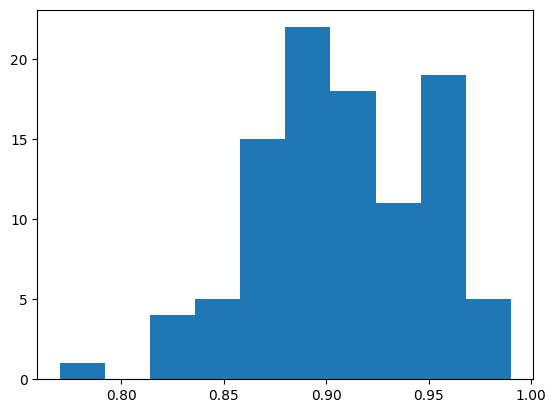

In [4]:
num_features_total = 1000
num_features_best = 100

N = 100
def experiment():
  # Dataset generation
  X = np.random.normal(size=(N, num_features_total))
  y = np.random.randint(2, size=N)

  # Feature selection:
  X_best = FeatureSelector(num_features_best).fit_transform(X, y)

  # Simple classification model
  model = LinearSVC()

  # Estimatin accuracy using cross-validation:
  return cross_val_score(model, X_best, y, scoring='accuracy', cv=10, n_jobs=-1).mean()

results = [experiment() for _ in range(100)]
plt.hist(results, bins=10);

## Task 1 (3 points)

Explain why the estimated model accuracy is not 50% on a dataset where targets were generated **independently from the features (!!!)**.

Find and fix the problem (don't change the dataset generation or its parameters - `num_features_total`, `num_features_best`, `N`).

*Hint: the problem is in the overall logic, and not a bug in the code.*

Mean accuracy before the fix: 0.907
Mean accuracy after the fix: 0.512


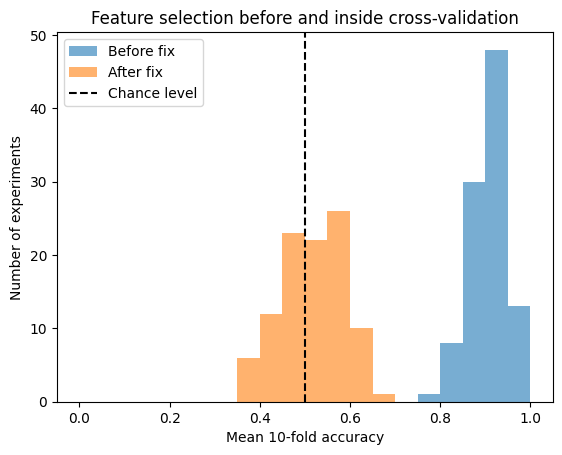

In [5]:
from sklearn.model_selection import StratifiedKFold

def corrected_experiment():
  # Generated data in the same way as before.
  X = np.random.normal(size=(N, num_features_total))
  y = np.random.randint(2, size=N)
  scores = []
  cv = StratifiedKFold(n_splits=10)

  for train_ids, val_ids in cv.split(X, y):
    # Selected features using only the training part of each fold.
    selector = FeatureSelector(num_features_best)
    X_train = selector.fit_transform(X[train_ids], y[train_ids])
    X_val = selector.transform(X[val_ids])

    model = LinearSVC()
    model.fit(X_train, y[train_ids])
    predictions = model.predict(X_val)
    scores.append(accuracy_score(y[val_ids], predictions))

  return np.mean(scores)

fixed_results = [corrected_experiment() for _ in range(100)]
print("Mean accuracy before the fix:", round(np.mean(results), 3))
print("Mean accuracy after the fix:", round(np.mean(fixed_results), 3))

plt.hist(results, bins=np.linspace(0, 1, 21), alpha=0.6, label="Before fix")
plt.hist(fixed_results, bins=np.linspace(0, 1, 21), alpha=0.6, label="After fix")
plt.axvline(0.5, color="black", linestyle="--", label="Chance level")
plt.xlabel("Mean 10-fold accuracy")
plt.ylabel("Number of experiments")
plt.title("Feature selection before and inside cross-validation")
plt.legend()
plt.show()

<!-- #changed -->
**Task 1 observations:**

The original code selected features using all labels before cross-validation. This included the validation labels, so information from the validation folds leaked into feature selection. With 1000 random features, some appeared related to the labels by chance. This made the original accuracy estimate too high.

The corrected code fitted a new feature selector on each training fold and applied it to the validation fold. After the fix, the average accuracy was close to 50%. Individual experiments varied because the samples were small and random.


## Task 2 (3 points)

Let's come back to Task 3 of Data Handling HW.
Build a model with KNeighborsClassifier to get a higher accuracy on 5-fold Cross Validation than you achieve using your previosly fitted model (you can just copy the params from the previous notebook).

Use `sklearn.model_selection.GridSearchCV` to find best parameters.  You may check the parameters'  description as follows:
``` python
help(KNeighborsClassifier)
```

In [7]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

data = pd.read_csv("train.csv", index_col='PassengerId')

X = data[["Fare", "Parch", "Pclass", "Sex", "SibSp"]].copy()
X["Sex"] = X["Sex"].map({"female": 0, "male": 1})
X["Fare"] /= 100
y = data["Survived"]

# Used identical folds for the old model and parameter search
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
old_model = KNeighborsClassifier(n_neighbors=7)
old_scores = cross_val_score(old_model, X, y, scoring="accuracy", cv=cv)

param_grid = {
    "n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}
search = GridSearchCV(KNeighborsClassifier(), param_grid, scoring="accuracy", cv=cv)
search.fit(X, y)

print("Old model mean accuracy:", round(old_scores.mean(), 4))
print("Best parameters:", search.best_params_)
print("Best mean accuracy:", round(search.best_score_, 4))
print("Improvement:", round(search.best_score_ - old_scores.mean(), 4))

# Collected the five validation scores for the selected parameters
best_scores = [search.cv_results_[f"split{i}_test_score"][search.best_index_]
               for i in range(5)]
comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "Old model": old_scores,
    "Best model": best_scores,
})
comparison

Old model mean accuracy: 0.7991
Best parameters: {'n_neighbors': 7, 'p': 1, 'weights': 'distance'}
Best mean accuracy: 0.8103
Improvement: 0.0112


,Fold,Old model,Best model
0,1,0.821229,0.815642
1,2,0.786517,0.808989
2,3,0.792135,0.792135
3,4,0.786517,0.797753
4,5,0.808989,0.837079


<!-- #changed -->
**Task 2 observations:**

The old model reached about 0.7991 mean accuracy on five folds. GridSearchCV selected 7 neighbors, distance-based weights and Manhattan distance (`p=1`). The mean accuracy increased to about 0.8103, an improvement of 1.12 percentage points.

Both models used the same features and folds. The old 0.84 result from Data Handling HW came from a different split, so it was not used for this comparison. The best CV score was used to select parameters, so it was not an independent test score.
